In [1]:
import logging
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import torch
import numpy as np
import pandas as pd
import json

logging.basicConfig(level=logging.INFO)

sys.path.append("Precipitate_Segmentation/src")
sys.path.append("Precipitate_Segmentation")

# Generation Parameters

In [2]:
NUM_SYNTH = 5
GEN_NAME = "testing_simple"
SEED = 3
PARAMS_PATH = Path("Precipitate_Segmentation/config/base_params.json")

SHOW_IMGS = False
SAVE_IMGS = True
SAVE_IMGS_DIR = Path("./data/")

# Training Parameters

In [3]:
REAL_IMGS_DIR = Path("./fin_data/labeled_wo_test")
TEST_IMGS_DIR = Path("./data/test")

MODEL_NAME = "mod_test"

RESULTS_DIR = Path("./results/")

ALLOW_OVERWRITE_DATASET = False
ALLOW_OVERWRITE_RUN = False

# Image Generation

In [4]:
from main import generate

generate(
    num=NUM_SYNTH,
    gen=GEN_NAME,
    img_params_path=PARAMS_PATH,
    img_save_path=str(SAVE_IMGS_DIR),
    show=SHOW_IMGS,
    save=SAVE_IMGS,
    seed=SEED,
)

# Load Images

In [5]:
SYNTH_DIR = SAVE_IMGS_DIR  # can be changed to work with previously generated images
LOAD_SYNTH_MODE = "basic"  # "basic" or "clustered"

# only used for "basic"
LOAD_NUM_SYNTH = 5  

# only used for "clustered"
CLUSTERS_BASE_COUNTS = (10, 13, 7, 9, 6)  
CLUSTERS_MULTIPLICATOR = 5
CLUSTERS_DIR_PREFIX = "cl"  # assumes the clustered images were generated like *{prefix}{i}/img.png

In [6]:
from precipseg import data

def load_paths(root: Path, n: int | None = None):
    img_paths = sorted(root.rglob("*/img.png"))
    if n is not None:
        img_paths = img_paths[:n]
    label_paths = [p.parent / "mask.png" for p in img_paths]
    return img_paths, label_paths

def load_clustered(synth_root: Path, base_counts, multiplier, prefix=CLUSTERS_DIR_PREFIX):
    img_paths = []
    for i, ratio in enumerate(base_counts):
        cluster = sorted(synth_root.rglob(f"*{prefix}{i}/img.png"))
        k = ratio * multiplier
        if len(cluster) < k:
            raise ValueError(f"Cluster {i}: requested {k}, found {len(cluster)}")
        img_paths += cluster[:k]
    return img_paths, [p.parent / "mask.png" for p in img_paths]

# test
test_img_paths, test_label_paths = load_paths(TEST_IMGS_DIR)
test_imgs = [data.read_image_normalized(p) for p in test_img_paths]
test_labels = [data.read_image_normalized(p) for p in test_label_paths]

# train real
real_img_paths, real_label_paths = load_paths(REAL_IMGS_DIR)

# train synthetic
if LOAD_SYNTH_MODE == "basic":
    synth_img_paths, synth_label_paths = load_paths(SYNTH_DIR, LOAD_NUM_SYNTH)
elif LOAD_SYNTH_MODE == "clustered":
    synth_img_paths, synth_label_paths = load_clustered(
        SYNTH_DIR, CLUSTERS_BASE_COUNTS, CLUSTERS_MULTIPLICATOR
    )
else:
    raise ValueError(f"Unknown LOAD_SYNTH_MODE={LOAD_SYNTH_MODE!r}")

train_img_paths = real_img_paths + synth_img_paths
train_label_paths = real_label_paths + synth_label_paths

print(f"Train: {len(real_img_paths)} real + {len(synth_img_paths)} synthetic ({LOAD_SYNTH_MODE}).")
print(f"Test: {len(test_img_paths)}.")

/home/vitkovicova/miniconda3/envs/training_env/lib/python3.12/site-packages/albumentations/__init__.py:24: UserWarning: A new version of Albumentations is available: 2.0.8 (you have 1.4.21). Upgrade using: pip install -U albumentations. To disable automatic update checks, set the environment variable NO_ALBUMENTATIONS_UPDATE to 1.
  check_for_updates()


Train: 45 real + 5 synthetic (basic).
Test: 6.


# Prepare Dataloaders

In [7]:
from precipseg import data

PATCH_SIZE = 256
X_CHANNELS = 3
BATCH_SIZE = 16
VAL_SIZE = 0.25


def build_dataloaders(img_paths, mask_paths, *, patch_size, x_channels, batch_size, val_size):
    train_aug = data.setup_augmentation(
        patch_size=patch_size,
        blur_sharp_power=0.8,
        noise_value=0.01,
        rotate_deg=20,
    )
    val_aug = data.setup_augmentation(patch_size=patch_size)

    return data.prepare_dataloaders_from_paths(
        img_paths,
        mask_paths,
        train_augmentation=train_aug,
        val_augmentation=val_aug,
        batch_size=batch_size,
        val_size=val_size,
        x_channels=x_channels,
    )

train_dl, val_dl = build_dataloaders(
    train_img_paths, train_label_paths,
    patch_size=PATCH_SIZE,
    x_channels=X_CHANNELS,
    batch_size=BATCH_SIZE,
    val_size=VAL_SIZE,
)

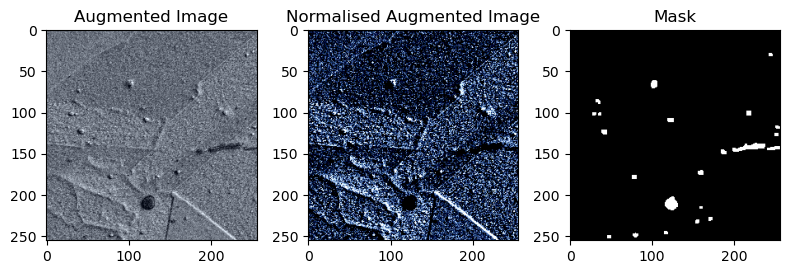

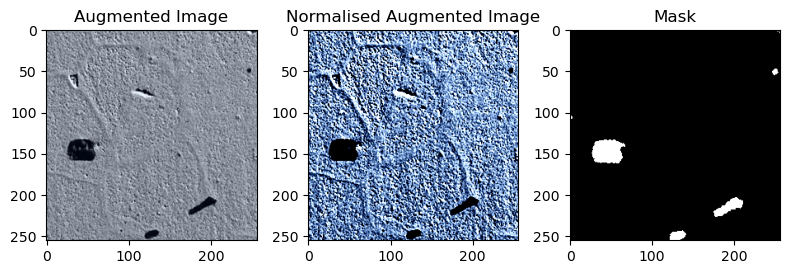

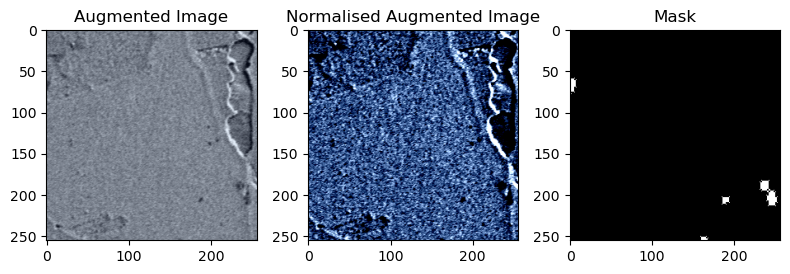

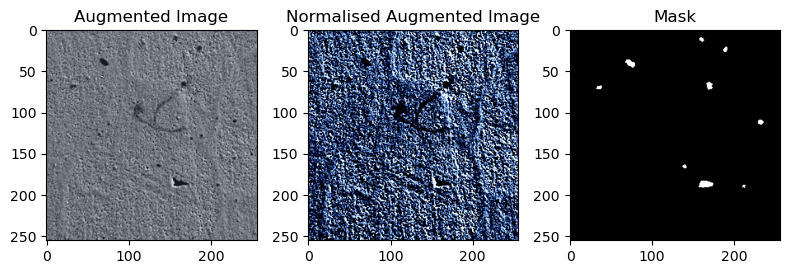

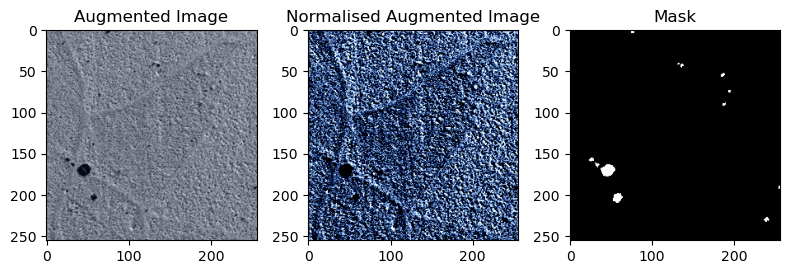

In [8]:
n_show = 5

for batch in train_dl:
    x, y = batch["x"], batch["y"]

    for shown, (img_t, mask_t) in enumerate(zip(x, y)):
        img = img_t.permute(1, 2, 0).cpu().numpy()
        mask = mask_t[0].cpu().numpy()

        img_vis = (img - img.min()) / (img.max() - img.min())

        plt.figure(figsize=(8, 4))

        plt.subplot(1, 3, 1)
        plt.imshow(img_vis, cmap="gray", vmin=0, vmax=1)
        plt.title("Augmented Image")

        plt.subplot(1, 3, 2)
        plt.imshow(img, cmap="gray")
        plt.title("Normalised Augmented Image")

        plt.subplot(1, 3, 3)
        plt.imshow(mask, cmap="gray", vmin=0, vmax=1)
        plt.title("Mask")

        plt.tight_layout()
        plt.show()

        if shown + 1 >= n_show:
            break
    break

# Model

In [9]:
from segmentation_models_pytorch import Unet

model = Unet(
    encoder_name="resnet18",
    encoder_weights="imagenet",
    in_channels=X_CHANNELS,
    classes=1,
    activation=None,
)

# Loss Selection

In [10]:
from precipseg.losses import make_loss, available_losses

print("Available losses:", available_losses())

LOSS_NAME = "focal_dice"
loss_fn = make_loss(LOSS_NAME)
# loss_fn = make_loss("focal_dice", gamma=2.0, alpha=0.25)
print("Chosen loss:", LOSS_NAME)

Available losses: ['focal', 'focal_dice', 'focal_tversky']
Chosen loss: focal_dice


# Training

In [11]:
from precipseg.training import train

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

models_dir = Path("./models")
models_dir.mkdir(parents=True, exist_ok=True)

checkpoint_path = models_dir / f"checkpoint-{MODEL_NAME}"

log_path = RESULTS_DIR / "log.txt"

In [12]:
from tqdm.contrib.logging import logging_redirect_tqdm

with logging_redirect_tqdm():
    train_loss, val_loss = train(
        model,
        train_dl,
        val_dl,
        loss_fn,
        checkpoint_path=checkpoint_path,
        patience=10,
        scheduler_patience=5,
        device=DEVICE,
        log_path=log_path)


torch.save(model.state_dict(), models_dir / f"{MODEL_NAME}.pt")

Training epochs: 0it [00:00, ?it/s]

Epoch 0: before_val_loss=inf -> 0.57744. Val IoU=0.009.
Epoch 2: before_val_loss=0.57744 -> 0.54311. Val IoU=0.010.
Epoch 3: before_val_loss=0.54311 -> 0.51819. Val IoU=0.025.
Epoch 4: before_val_loss=0.51819 -> 0.50680. Val IoU=0.032.
Epoch 5: before_val_loss=0.50680 -> 0.50029. Val IoU=0.101.
Epoch 6: before_val_loss=0.50029 -> 0.49093. Val IoU=0.279.
Epoch 11: before_val_loss=0.49093 -> 0.47769. Val IoU=0.257.
Epoch 12: before_val_loss=0.47769 -> 0.45822. Val IoU=0.331.
Epoch 13: before_val_loss=0.45822 -> 0.42868. Val IoU=0.373.
Epoch 21: before_val_loss=0.42868 -> 0.42004. Val IoU=0.396.
Epoch 22: before_val_loss=0.42004 -> 0.39837. Val IoU=0.477.
Epoch 27: before_val_loss=0.39837 -> 0.37861. Val IoU=0.425.
Epoch 30: before_val_loss=0.37861 -> 0.36565. Val IoU=0.406.
Epoch 33: before_val_loss=0.36565 -> 0.31698. Val IoU=0.465.
Epoch 34: before_val_loss=0.31698 -> 0.30108. Val IoU=0.445.
Epoch 35: before_val_loss=0.30108 -> 0.28041. Val IoU=0.474.
Epoch 37: before_val_loss=0.28041 

# Predictions

In [13]:
from precipseg import predictions 

test_preds = predictions.segment_many(model, test_imgs, device=DEVICE, x_channels=X_CHANNELS)


Segmenting: 100%|██████████| 6/6 [00:00<00:00, 16.04it/s]


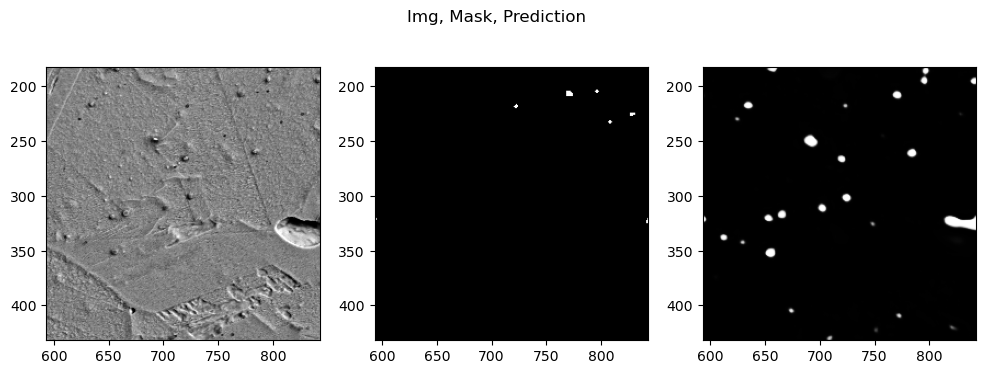

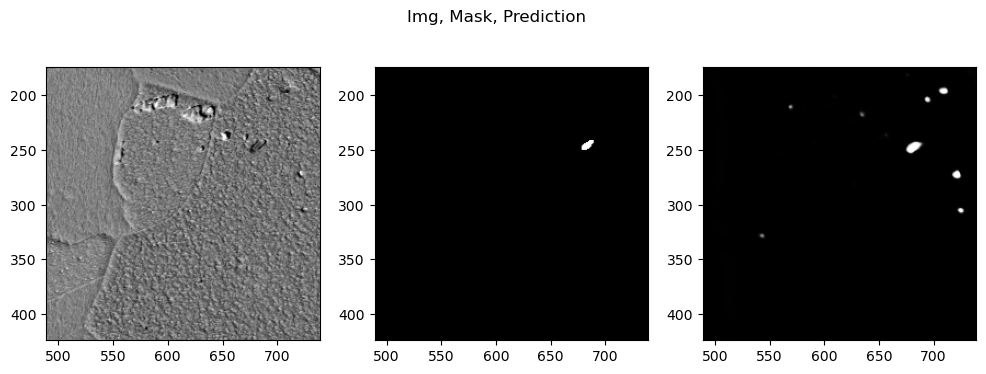

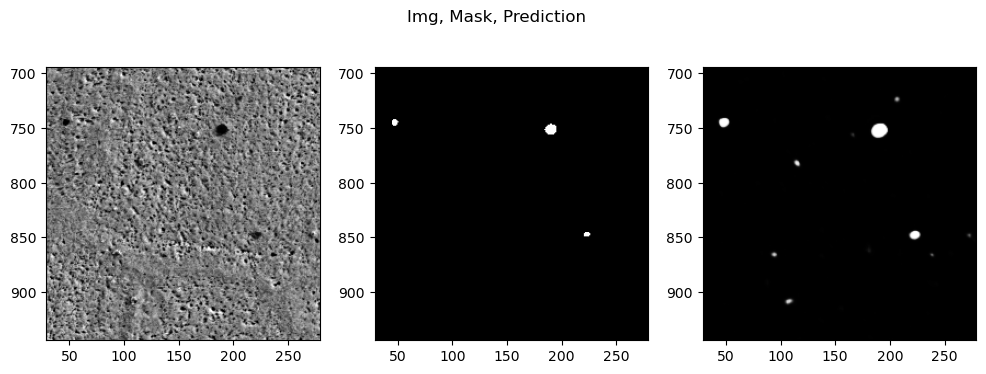

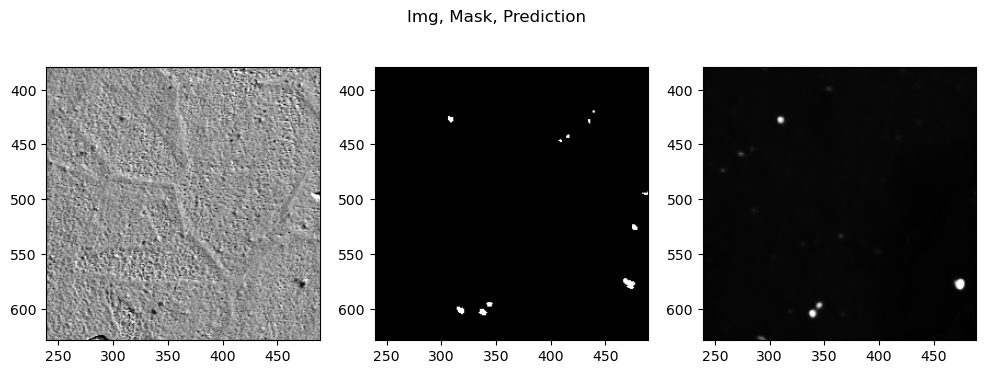

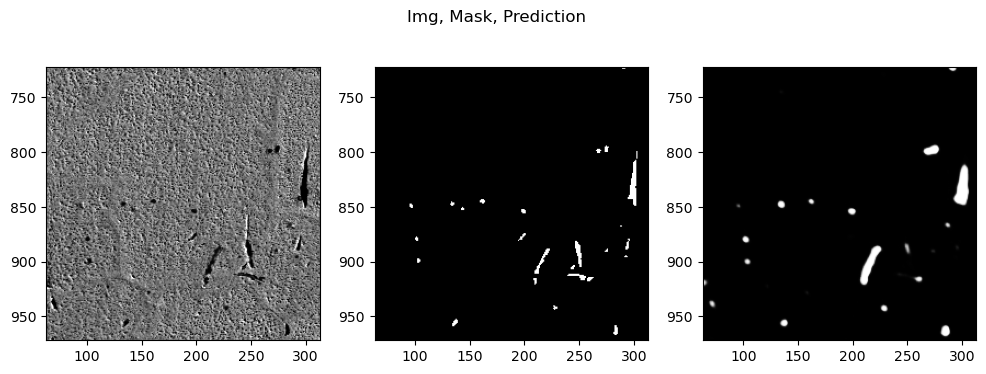

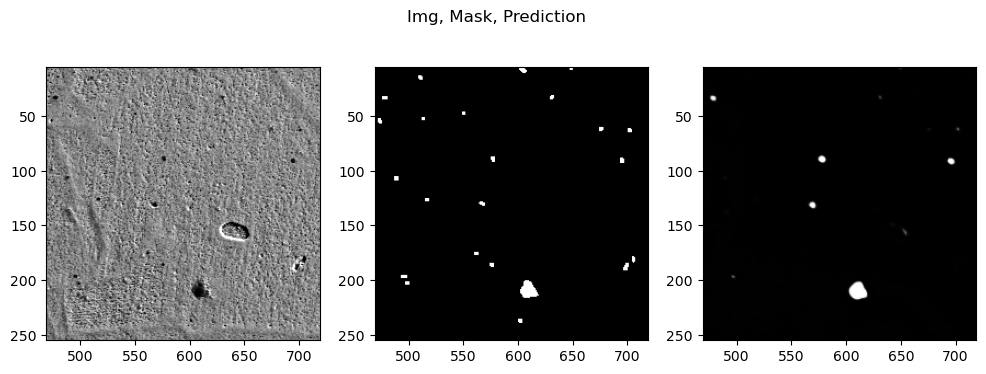

In [14]:
for img, label, pred in zip(test_imgs, test_labels, test_preds):
    fig, axs = plt.subplots(1, 3, figsize=(12, 4))
    axs[0].imshow(img,vmin=0, vmax=1, cmap="gray")
    axs[1].imshow(label,vmin=0, vmax=1, cmap="gray")
    axs[2].imshow(pred,vmin=0, vmax=1, cmap="gray")

    plt.suptitle("Img, Mask, Prediction")

    H, W = img.shape
    crop_w, crop_h = 250, 250

    x0 = np.random.randint(0, W - crop_w)
    y0 = np.random.randint(0, H - crop_h)
    x1 = x0 + crop_w
    y1 = y0 + crop_h

    for ax in axs:
        ax.set_xlim(x0, x1)
        ax.set_ylim(y1, y0)
    plt.show()

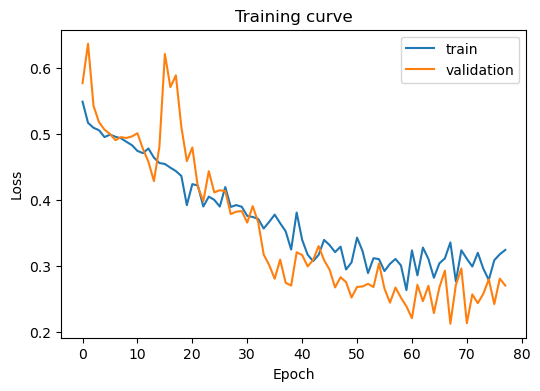

In [15]:
plt.figure(figsize=(6,4))
plt.plot(train_loss, label="train")
plt.plot(val_loss, label="validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training curve")
plt.legend()
plt.show()

# Save Results

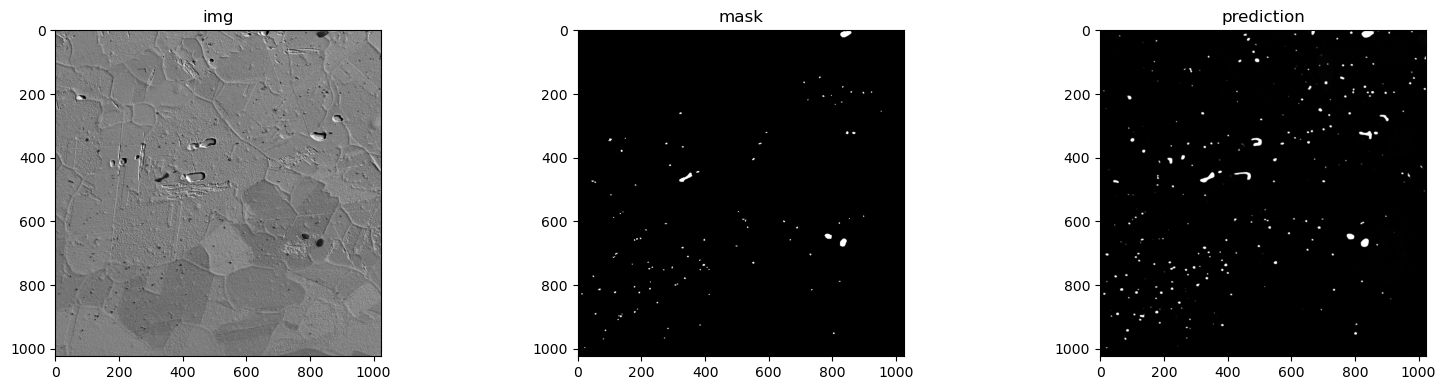

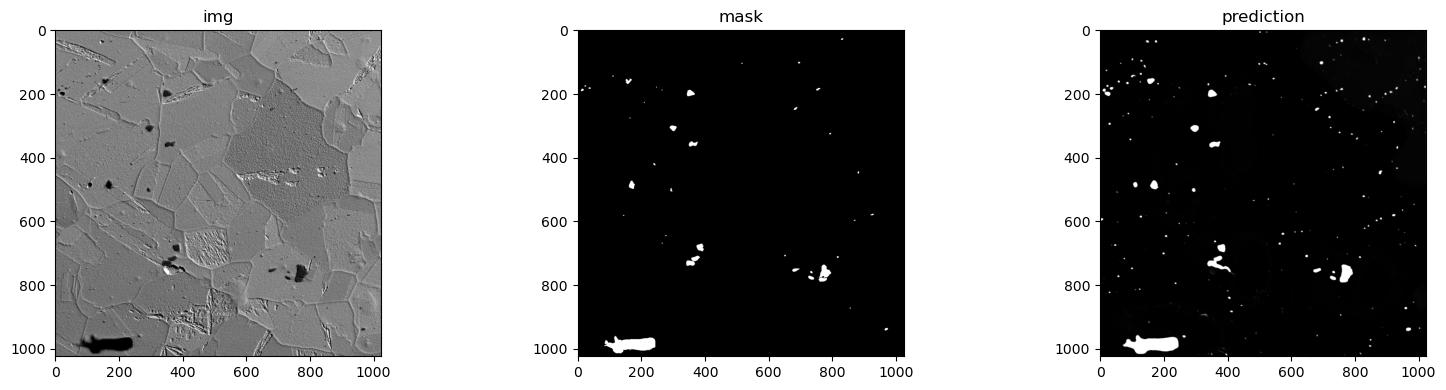

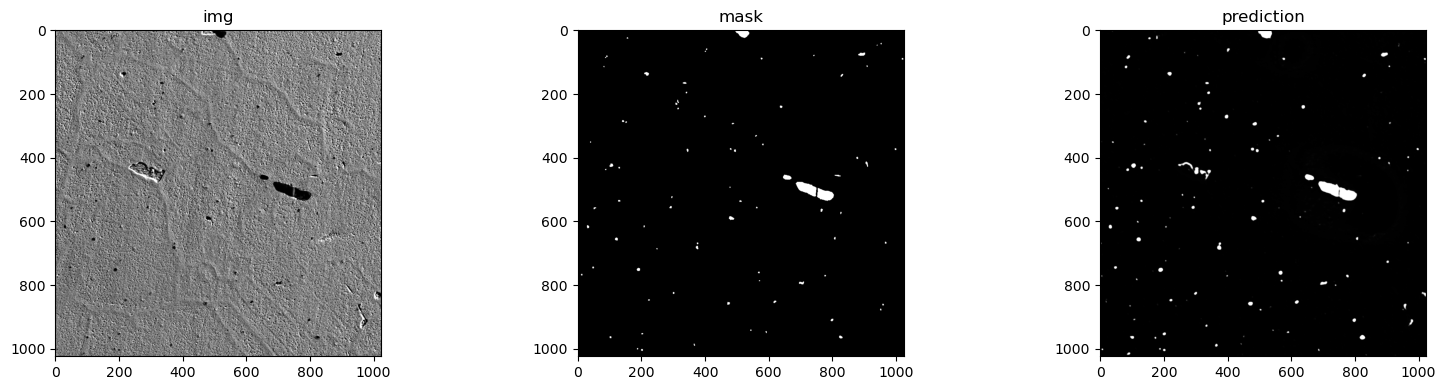

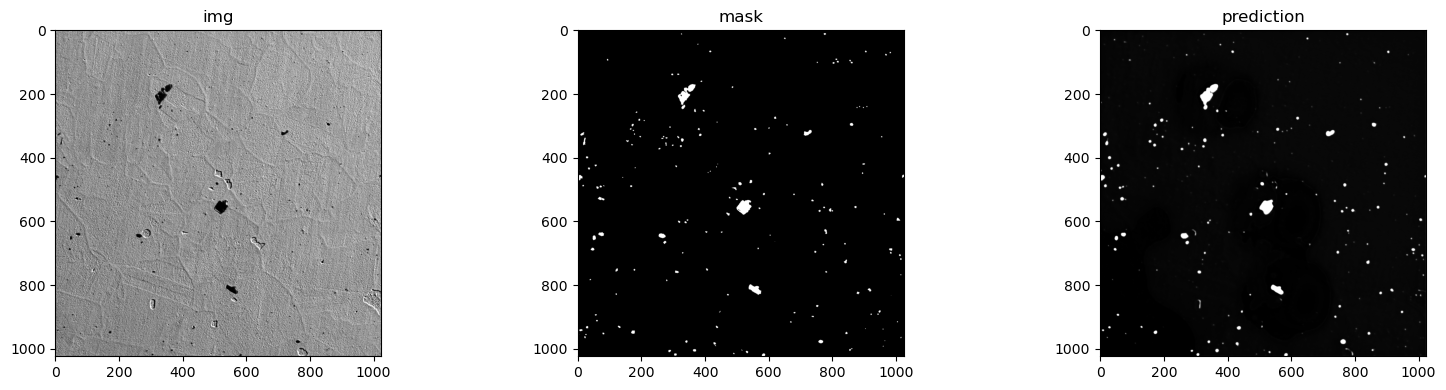

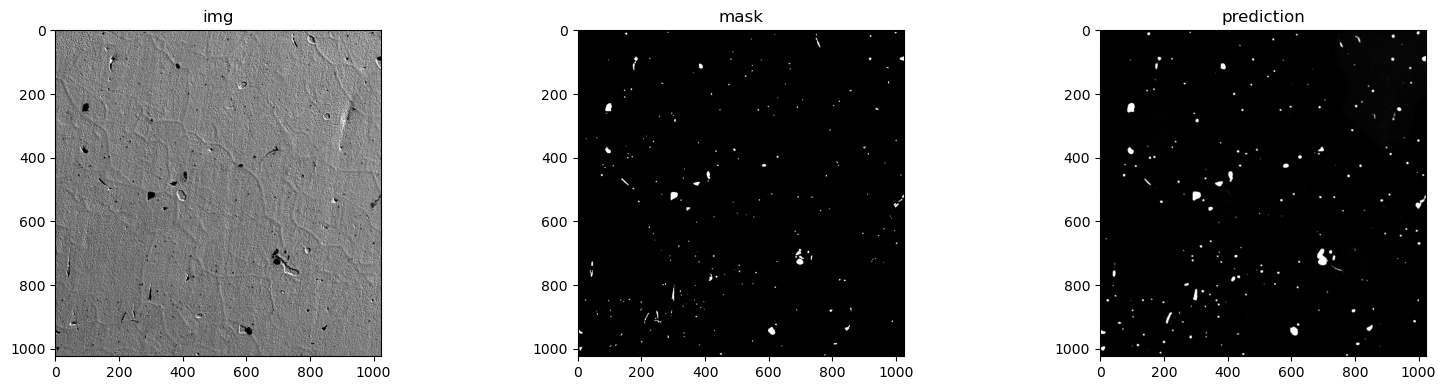

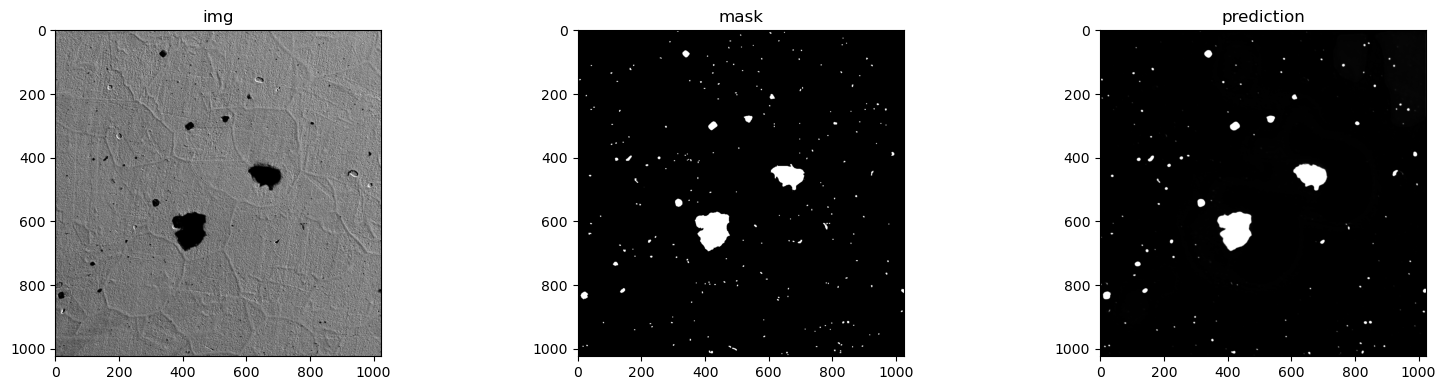

In [16]:
results_dir = Path("./results") / MODEL_NAME
results_dir.mkdir(parents=True, exist_ok=True)

def save_image_results():
    i = 1
    for img, label, pred in zip(test_imgs, test_labels, test_preds):
        fig, axs = plt.subplots(1,3,figsize=(16,4))
        for ax, title, im in zip(axs, ["img", "mask", "prediction"], [img, label, pred]):
            ax.imshow(im,vmin=0, vmax=1, cmap='gray')
            ax.set_title(title)

        plt.tight_layout()
        fig.savefig(results_dir/f"res{i}.png")
        plt.show()
        i += 1
    
save_image_results()

In [18]:
from precipseg.metrics import binary_iou, binary_dice, binary_precision_recall_f1

def metrics_by_threshold(labels, preds, thresholds):
    rows = []
    for thr in thresholds:
        ious, dices, ps, rs, f1s = [], [], [], [], []
        for gt, pr in zip(labels, preds):
            ious.append(binary_iou(gt, pr, threshold=float(thr)))
            dices.append(binary_dice(gt, pr, threshold=float(thr)))
            p, r, f1 = binary_precision_recall_f1(gt, pr, threshold=float(thr))
            ps.append(p); rs.append(r); f1s.append(f1)

        rows.append({
            "threshold": float(thr),
            "iou": float(np.nanmean(ious)),
            "dice": float(np.nanmean(dices)),
            "precision": float(np.nanmean(ps)),
            "recall": float(np.nanmean(rs)),
            "f1": float(np.nanmean(f1s)),
        })
    return pd.DataFrame(rows)

thresholds = np.linspace(0.10, 0.95, 10)
df = metrics_by_threshold(test_labels, test_preds, thresholds)

df.to_csv(results_dir / "metrics_by_threshold.csv", index=False)

In [19]:
# Save best (pick best by F1)
best = df.loc[df["f1"].idxmax()].to_dict()
with open(results_dir / "best.json", "w") as f:
    json.dump({"selection_rule": "best_f1", "best": best}, f, indent=2)

df

,threshold,iou,dice,precision,recall,f1
0,0.100000,0.442722,0.599807,0.464262,0.922959,0.599807
1,0.194444,0.491237,0.645597,0.524330,0.906277,0.645597
2,0.288889,0.510659,0.663590,0.551564,0.893681,0.663590
3,0.383333,0.525040,0.676711,0.572760,0.884017,0.676711
4,0.477778,0.536222,0.686810,0.590772,0.874203,0.686810
5,0.572222,0.546703,0.696216,0.608586,0.864482,0.696216
6,0.666667,0.557614,0.705869,0.627448,0.854609,0.705869
7,0.761111,0.568066,0.715121,0.648411,0.841316,0.715121
8,0.855556,0.580141,0.725843,0.675282,0.823610,0.725843
9,0.950000,0.594295,0.738104,0.722172,0.784318,0.738104
